Single allele groupped structue models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/core_identification/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/core_identification_weights/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01']

In [4]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [5]:
ALLELES

['HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01']

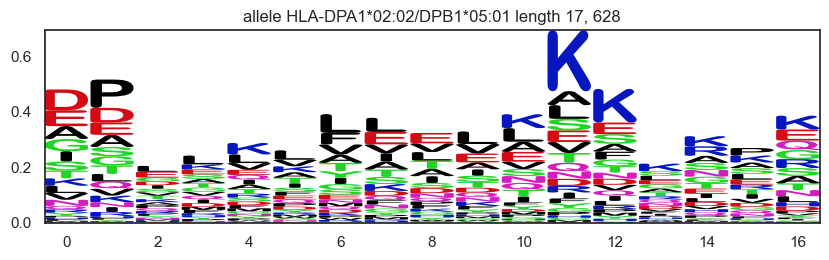

In [6]:
target_allele = ALLELES[0]
target_length = 17

binders_array = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(binders_array, f"allele {target_allele} length {target_length}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [52]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
# ALLELES = sorted([ 'HLA-A*03:01'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])

sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
 'HLA-DRB5*01:01'])

ALLELES = sorted([#'HLA-DQA1*05:01/DQB1*02:01', 
                  'HLA-DPA1*02:02/DPB1*05:01'
                 ])

combination_size = 1

TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
TARGET_LENGTHS=  [12, 13,14, 15, 16,17, 18]

# TARGET_LENGTHS= [15]
# TARGET_LENGTHS= [9]
check_peptides = True

In [53]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['HLA-DPA1*02:02/DPB1*05:01'])

## Motif for train data

In [54]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in TARGET_LENGTHS}

{12: 420, 13: 790, 14: 1241, 15: 1231, 16: 927, 17: 628, 18: 403}

In [55]:
for allele_name in ALLELES:
    for split_num in range(TOTAL_SPLITS):
        new_dict = dict()
        for tl in TARGET_LENGTHS:
            new_dict[tl] = per_allele_per_kfold_per_length_binders_train[allele_name][split_num][tl]
        per_allele_per_kfold_per_length_binders_train[allele_name][split_num] = new_dict


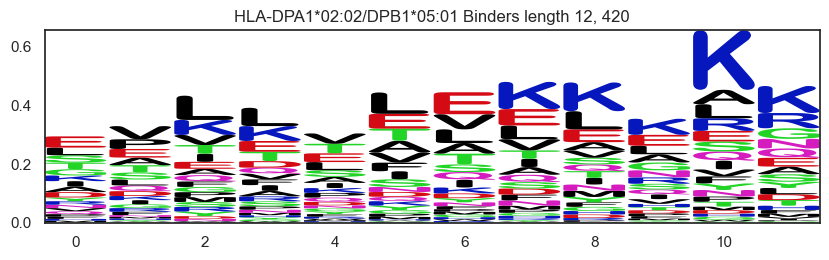

In [56]:

target_length = 12
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [57]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*02:02/DPB1*05:01
Length 16: HLA-DPA1*02:02/DPB1*05:01 - 927 
Length 17: HLA-DPA1*02:02/DPB1*05:01 - 628 
Length 18: HLA-DPA1*02:02/DPB1*05:01 - 403 
Length 12: HLA-DPA1*02:02/DPB1*05:01 - 420 
Length 13: HLA-DPA1*02:02/DPB1*05:01 - 790 
Length 14: HLA-DPA1*02:02/DPB1*05:01 - 1241 
Length 15: HLA-DPA1*02:02/DPB1*05:01 - 1231 


In [58]:
ALLELES

['HLA-DPA1*02:02/DPB1*05:01']

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

# Calculate weight for peptide. How often 9-mer from this peptide will be inside data

In [59]:
np.concatenate(list(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0].values())).shape

(5640,)

In [60]:
from tqdm import tqdm
def get_number_of_occurences(core, whole_data_peptides):
    counter = 0
    for peptide in whole_data_peptides:
        counter += peptide.count(core)
    return counter
    
def get_core_summary_score(per_allele_per_split_per_length_data, core_len):
    result_weights_data = dict()
    
    for allele_name, per_split_data in per_allele_per_split_per_length_data.items():
        result_weights_data[allele_name] = dict()
        for split_num, per_length_data in per_split_data.items():
            result_weights_data[allele_name][split_num] = dict()
            total_split_data = np.concatenate(list(per_length_data.values()))
            for target_length, data_peptides in tqdm(per_length_data.items()):
                result_weights_data[allele_name][split_num][target_length] = list()
                for target_peptide in data_peptides:
                    score_for_peptide = 0
                    number_of_cores = 1 + len(target_peptide) - core_len


                    for core_start in range(0, len(target_peptide) - core_len + 1):
                        current_core = target_peptide[core_start: core_start+core_len]
                        number_for_given_core = get_number_of_occurences(current_core, total_split_data)
                        score_for_peptide += number_for_given_core
                    score_for_peptide = score_for_peptide / number_of_cores if len(target_peptide) > core_len else 1
  
                   # score_for_peptide = (score_for_peptide + 1)/len(total_split_data)
                    result_weights_data[allele_name][split_num][target_length].append(1/score_for_peptide)
    return result_weights_data
                        
                
                
 #####



            
    
    


In [61]:
result_weights_data = get_core_summary_score(per_allele_per_kfold_per_length_binders_train_old, 9)

100%|███████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:28<00:00,  4.07s/it]


## See some weights

In [62]:
current_split = 0
current_allele = ALLELES[0]
current_length = 15
core_len = 9

selected_peptides = per_allele_per_kfold_per_length_binders_train_old[current_allele][current_split][current_length][0:5]

In [63]:
selected_peptides

array(['GPEKTRSQLLIMDRA', 'VVESTGVFTTMEKAG', 'FLQKKNHLIEEINDE',
       'QAMGSFLSVAKGSDE', 'YLATLETLTKHYGAE'], dtype=object)

In [64]:
per_length_data = per_allele_per_kfold_per_length_binders_train_old[current_allele][current_split]
total_split_data = np.concatenate(list(per_length_data.values()))

selected_scores = list()

occurences_for_peptide_core = dict()

for target_peptide in selected_peptides:
    score_for_peptide = 0
    number_of_cores = 1 + len(target_peptide) - core_len
    occurences_for_peptide_core[target_peptide] = dict()
    for core_start in range(0, len(target_peptide) - core_len + 1):
        current_core = target_peptide[core_start: core_start+core_len]
        assert len(current_core) == core_len
        number_for_given_core = get_number_of_occurences(current_core, total_split_data)
        occurences_for_peptide_core[target_peptide][current_core] = number_for_given_core
        score_for_peptide += number_for_given_core
        
    score_for_peptide = (score_for_peptide) /number_of_cores
  #  score_for_peptide = (score_for_peptide + 1) / (1 +(len(target_peptide) - core_len)) if len(target_peptide) > core_len else 1

    selected_scores.append(1/score_for_peptide)




In [65]:
selected_scores

[0.5, 0.061946902654867256, 1.0, 0.38888888888888884, 0.10144927536231883]

In [73]:
occurences_for_peptide_core

{'GPEKTRSQLLIMDRA': {'GPEKTRSQL': 2,
  'PEKTRSQLL': 2,
  'EKTRSQLLI': 2,
  'KTRSQLLIM': 2,
  'TRSQLLIMD': 2,
  'RSQLLIMDR': 2,
  'SQLLIMDRA': 2},
 'VVESTGVFTTMEKAG': {'VVESTGVFT': 3,
  'VESTGVFTT': 7,
  'ESTGVFTTM': 12,
  'STGVFTTME': 17,
  'TGVFTTMEK': 22,
  'GVFTTMEKA': 26,
  'VFTTMEKAG': 26},
 'FLQKKNHLIEEINDE': {'FLQKKNHLI': 1,
  'LQKKNHLIE': 1,
  'QKKNHLIEE': 1,
  'KKNHLIEEI': 1,
  'KNHLIEEIN': 1,
  'NHLIEEIND': 1,
  'HLIEEINDE': 1},
 'QAMGSFLSVAKGSDE': {'QAMGSFLSV': 2,
  'AMGSFLSVA': 3,
  'MGSFLSVAK': 3,
  'GSFLSVAKG': 3,
  'SFLSVAKGS': 3,
  'FLSVAKGSD': 3,
  'LSVAKGSDE': 1},
 'YLATLETLTKHYGAE': {'YLATLETLT': 10,
  'LATLETLTK': 13,
  'ATLETLTKH': 13,
  'TLETLTKHY': 11,
  'LETLTKHYG': 10,
  'ETLTKHYGA': 7,
  'TLTKHYGAE': 5}}

In [74]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [75]:
per_allele_per_kfold_per_length_binders_test_old[allele_name][split_num][15][0], per_allele_per_kfold_per_length_binders_test_old[allele_name][split_num][15][1]

('FLQKKNHLIEEINDE', 'YLATLETLTKHYGAE')

In [76]:
result_weights_data[allele_name][split_num][15][0], result_weights_data[allele_name][split_num][15][1]

(0.5, 0.09210526315789473)

In [77]:
import seaborn as sns

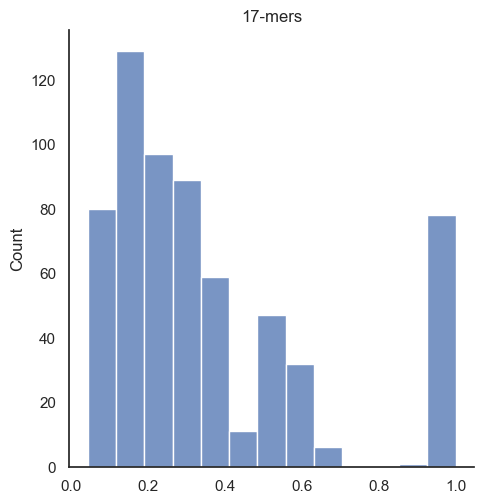

In [78]:
tl = 17
ax = sns.displot(result_weights_data[allele_name][split_num][tl]).set(title=f'{tl}-mers')


## 2.3 Weights for data based on counts

In [79]:
sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
                                        (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
                                        (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]

In [80]:
sub_count_df_train['cnt'].sum()

5640

In [81]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 13.428571428571429}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 7.139240506329114}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 4.544721998388397}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 4.581640942323315}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 6.084142394822006}
Weights for lentgh 17 are {'HLA-DPA1*02:02/DPB1*05:01': 8.980891719745223}
Weights for lentgh 18 are {'HLA-DPA1*02:02/DPB1*05:01': 13.995037220843672}
Total data length for split 1 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 13.39667458432304}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 7.139240506329114}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 4.544721998388397}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 4.581640942323315}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 6.084142394822006}
Weights for lentgh 17 

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [18]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



## 2.2 Train
### 2.2.1 Define treshold

In [19]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

2.9968214285714287

### 2.2.2 Prepare  initial grouped structure models

In [32]:
# Training params
algorithm = 'viterbi'

params = dict()


# params['st'] = 7
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 65
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0
# params['groups'] = 7
# params['states_per_group'] = 1
# params['use_pseudocount'] = True


# params['st'] = 21
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 60
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 100
# params['transition_pseudocount'] = 1
# params['verbose'] = True
# params['lr_decay'] = 0.9
# params['edge_inertia'] = 0.4
# params['distribution_inertia'] = 0.4
# params['groups'] = 7
# params['states_per_group'] = 3
# params['model_complexity'] = 3
# params['use_pseudocount'] = True


params['st'] = 14
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 90
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 20
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 2
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 20
params['anchor_top_aas'] = 5
params['anchor_states'] = True





assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None

In [33]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    model_complexity =params['model_complexity']
)

states will be groups:14 + joiners:6 + start/end cycles:6


In [34]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [35]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [36]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=28 |E|=74

## Prepare models

In [37]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides,
                equal_probs_for_cycle=params['equal_probs_for_cycle'],
                tie_cycle_states=params['tie_cycle_states'],
                model_complexity=params['model_complexity']
            )



            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be groups:14 + joiners:6 + start/end cycles:6
states will be

## Do training

In [38]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        #per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        per_kfold_per_length_weights =  result_weights_data[allele_name]

       
        


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                       n_jobs=3)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



run 0
split 0
train size 5640
Shuffling for fairness 
Simple training: Train Length 5640, init_batch_size None
Example of data ['R', 'L', 'E', 'K', 'R', 'N', 'S', 'D', 'L', 'L', 'L', 'L', 'V', 'D', 'T', 'H']
Use pseudocount is True
[1] Improvement: 13854.759305771557	Time (s): 0.632
[2] Improvement: 4057.5456804298738	Time (s): 0.6318
[3] Improvement: 1356.4361497315404	Time (s): 0.6315
[4] Improvement: 511.0479169485043	Time (s): 0.6223
[5] Improvement: 261.8951105584856	Time (s): 0.6157
[6] Improvement: 217.13911874537007	Time (s): 0.6318
[7] Improvement: 289.7303762623342	Time (s): 0.6531
[8] Improvement: 327.52800274745096	Time (s): 0.6162
[9] Improvement: 305.23709450339084	Time (s): 0.6325
[10] Improvement: 280.16675926963217	Time (s): 0.6217
[11] Improvement: 247.22044124887907	Time (s): 0.6431
[12] Improvement: 204.27575854511815	Time (s): 0.6225
[13] Improvement: 266.92669095730525	Time (s): 0.6514
[14] Improvement: 282.81668443928356	Time (s): 0.6385
[15] Improvement: 186.203

In [39]:

# Sort by score
per_name_new_models = dict()
per_name_histories = dict()
for split_num in range(TOTAL_SPLITS):
    for allele_name in ALLELES:
        df = pd.DataFrame({"model": np.arange(NUM_RUNS), 
                          "log_probability": [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].log_probabilities[-1]
                                             for i in range(NUM_RUNS)],
                          "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                                             for i in range(NUM_RUNS)]})
        df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
        for new_index, model_run_num in zip(np.arange(len(df)), df.model):
            original_model =  per_allele_per_run_per_split_prepared_models[allele_name][model_run_num][split_num]
            original_history = per_allele_per_run_per_split_new_histories[allele_name][model_run_num][split_num]
            original_model_name = original_model.name
            rest_part = original_model_name.split("_", 1)[1]
            new_name = f"{new_index}_{rest_part}"
            original_model.name = new_name
            per_name_new_models[new_name] = original_model
            per_name_histories[new_name] = original_history
per_name_models = per_name_new_models
        
        

In [40]:
for name, model in per_name_models.items():
    history = per_name_histories[name]
    save_model(TARGET_PATH_TO_RESULTS, model,history)
    

In [41]:
per_name_models = per_name_new_models

In [42]:
from hmm_visualization_methods import *

<AxesSubplot: >

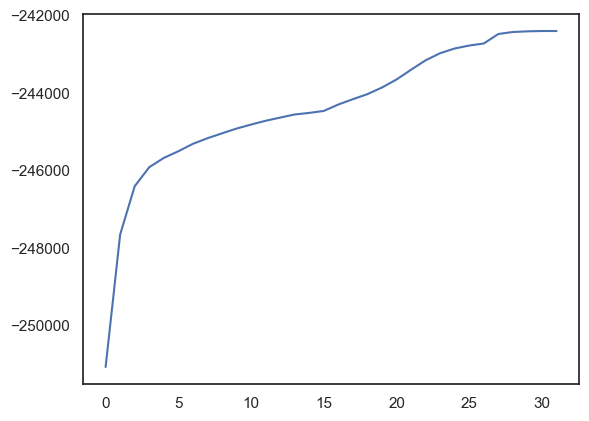

In [43]:
sns.lineplot(
    per_name_histories[
        list(per_name_histories.keys())[1]
    ].log_probabilities)

In [44]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
CPU times: total: 266 ms
Wall time: 6.03 s


In [45]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
CPU times: total: 3min 17s
Wall time: 3min 21s


In [46]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (3_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (4_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (5_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (6_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting gr

## Training steps

In [47]:

params['st'] = 21
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 3
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 300

In [48]:
allele_name = ALLELES[0]
per_kfold_per_length_train_data = per_allele_per_kfold_per_length_binders_train[allele_name]
per_kfold_per_length_test_data = per_allele_per_kfold_per_length_binders_test[allele_name]
per_kfold_per_length_weights_for_data = per_allele_per_kfold_per_length_weights[allele_name]
split_num = 0
target_lengths = TARGET_LENGTHS
per_length_current_weights = per_kfold_per_length_weights_for_data[split_num]
per_length_data = per_kfold_per_length_train_data[split_num]

per_length_test_data = per_kfold_per_length_test_data[split_num]
per_length_counts = {target_length: len(per_length_data[target_length]) for target_length in target_lengths}

# list_of_arrays = [per_length_data[target_length] for target_length in target_lengths]
# list_of_arrays_for_weights = [np.array(per_length_current_weights[target_length]) for target_length in
#                               target_lengths]
# list_of_test_arrays = [per_length_test_data[target_length] for target_length in target_lengths]
# binders_array = np.concatenate(list_of_arrays)
# weights_array = np.concatenate(list_of_arrays_for_weights)
#
# binders_test_array = np.concatenate(list_of_test_arrays)

binders_array = np.array([per_length_data[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_data[target_length]))], dtype=object)
weights_array = np.array([per_length_current_weights[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_current_weights[target_length]))], dtype=object)

binders_test_array = np.array([per_length_test_data[target_length][i] for target_length in target_lengths
                               for i in range(len(per_length_test_data[target_length]))], dtype=object)
print("split {}".format(split_num))
print("train size {}".format(len(binders_array)))
# total_length = len(binders_array)
#  weights = [1 - per_length_counts[len(peptide)]/total_length for peptide in binders_array]
# print("weights for lengths {}".format({key: 1 - value/total_length for key, value in per_length_counts.items()}))
print("Shuffling for fairness ")

rng = np.random.default_rng()
# shuffle train data and weights in unison
new_indexes = rng.permutation(len(binders_array))
binders_array = binders_array[new_indexes]
weights_array = weights_array[new_indexes]

# just shuffle test data
rng.shuffle(binders_test_array)
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sample_X_test = np.array([[char for char in item] for item in binders_test_array], dtype=object)

NameError: name 'per_allele_per_kfold_per_length_weights' is not defined

In [ ]:

sequence_generator = sample_X
sequence_test_generator = SequenceGenerator(sample_X_test)
data_generator = sequence_generator


In [ ]:
data_generator = SequenceGenerator(sample_X, weights_array)

In [ ]:
batches = [batch for batch in data_generator.batches()]

In [ ]:
len(batches)

In [ ]:
from hmm_visualization_methods import *

model_to_train = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states']
)
with open('model.png', 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)
    
    
def step(iteration):
    print(iteration)
    list_of_summaries = list()
    result = 0
    batch_size = len(binders_array)
    for set_num in range(1):
        cur_batch = batches[set_num*batch_size:(set_num+1)*batch_size]
        epoch_probs = list()
        for i, batch in enumerate(cur_batch):
            seq, weights = batch

            result += model_to_train.summarize(seq, weights, algorithm='viterbi')

        total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]
        result_summaries[f"{iteration}_{set_num}"] = total_summaries


            # print(list_of_summaries[-1])
        step_size = None
        pseudocount = None
        transition_pseudocount = params['transition_pseudocount']
        emission_pseudocount = params['emission_pseudocount']
        use_pseudocount = params['use_pseudocount']
        edge_inertia = params['edge_inertia']
        distribution_inertia = params['distribution_inertia']

    #         new_edge_inertia = None if edge_inertia is None else 1 - ((1 - edge_inertia) * (2 + iteration) ** -params['lr_decay'])
    #         new_dist_inertia = None if edge_inertia is None else 1 - ((1 - distribution_inertia) * (2 + iteration) ** -params['lr_decay'])





        #  inertia=None, pseudocount=None,
        # transition_pseudocount=0.0, emission_pseudocount=0.0,
        # use_pseudocount=False, edge_inertia=0.0, distribution_inertia=0.0)


        model_to_train.from_summaries(inertia=step_size, 
                             pseudocount=pseudocount, 
                             transition_pseudocount=transition_pseudocount,
                             emission_pseudocount= emission_pseudocount,
                             use_pseudocount= use_pseudocount,
                             edge_inertia = edge_inertia, 
                             distribution_inertia=distribution_inertia)
        model_to_train.clear_summaries()
        model_to_train.update_transitions()
    probs.append(result)
    
    
    

result_summaries = dict()
iterations = 50
probs = list()
for iteration in range(iterations):
    step(iteration)
    
   



    # plot_distributions_for_states(prepared_model,f"test{it}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
    # make_pyviz_graph(prepared_model, f"test{it}/", precision=3)

In [504]:
iter_num = 0
batch_num = 0

l = [item[0] for item in result_summaries[f"{iter_num}_{batch_num}"]]
df  = pd.DataFrame.from_dict(l, orient='columns')
df['Total']= df.sum(axis=1)
df

,A,C,D,E,F,G,H,I,K,L,...,N,P,Q,R,S,T,V,W,Y,Total
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [241]:
peptide = "".join(batches[2700][0][0])

In [34]:
[item[1].name for item in model_to_train.viterbi(peptide)[1]]

['grouped_model-start',
 's027',
 's027',
 's027',
 's027',
 's021',
 's000',
 's004',
 's006',
 's009',
 's013',
 's017',
 's020',
 's026',
 's031',
 's031',
 's031',
 's031',
 's031',
 's031',
 'grouped_model-end']

In [35]:
pd.DataFrame(model_to_train.backward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,-59.202336,-58.855399,-58.984566,-57.867649,-58.260476,-57.829876,-63.302314,-63.454178,-63.537431,-59.626905,...,-84.568001,-59.025789,-51.567622,-53.625446,-54.416348,-84.813867,-59.267263,-58.237746,-51.873672,-inf
1,-58.036613,-57.767035,-59.089318,-54.804866,-55.197196,-54.767783,-55.743951,-55.439733,-55.662311,-61.119696,...,-81.631236,-55.814071,-48.418127,-50.548820,-51.473632,-81.877102,-56.055544,-55.283072,-48.798895,-inf
2,-50.524922,-50.188519,-50.326253,-51.862235,-52.253310,-51.816765,-51.544004,-51.237747,-51.461069,-50.869938,...,-77.478493,-51.418326,-43.990814,-50.313803,-51.614642,-77.724360,-51.659799,-51.678551,-44.392764,-inf
3,-44.624449,-44.770778,-44.563056,-46.340072,-45.640404,-46.302538,-49.674564,-49.772801,-49.574636,-49.379591,...,-74.262874,-48.202235,-40.840026,-47.594290,-46.691465,-74.508740,-48.443708,-48.657037,-41.241789,-inf
4,-46.033762,-45.769310,-47.097459,-43.256284,-43.648758,-43.219216,-43.506998,-43.632249,-43.496063,-46.140992,...,-71.182259,-45.139985,-38.402361,-41.456395,-44.729665,-71.428126,-45.381459,-45.549120,-40.644411,-inf
5,-42.791580,-41.723594,-41.791332,-39.943982,-40.336971,-39.906659,-39.958934,-40.084332,-39.947845,-40.035354,...,-67.532430,-41.772402,-40.151418,-38.169140,-43.473888,-67.778297,-42.013875,-42.009870,-40.230907,-inf
6,-31.906948,-32.053322,-31.845516,-38.728122,-38.314594,-38.538346,-37.848953,-37.973649,-37.836519,-37.833944,...,-64.419044,-39.172569,-45.690330,-39.844878,-40.411936,-64.664911,-39.414042,-38.834059,-41.419234,-inf
7,-32.671433,-32.817798,-32.610014,-31.632250,-30.931162,-31.595655,-36.181254,-36.218564,-35.898087,-34.315424,...,-61.338430,-36.110319,-43.377819,-40.542989,-38.878416,-61.584296,-36.351792,-35.726142,-40.211392,-inf
8,-33.916396,-33.648287,-35.009745,-31.871121,-31.695675,-31.947574,-28.797755,-28.923053,-28.786320,-32.647770,...,-58.257815,-33.048069,-40.945624,-36.072827,-36.874470,-58.503682,-33.289543,-32.618224,-37.234575,-inf
9,-34.020269,-33.683449,-33.815074,-30.541354,-30.933960,-30.504113,-29.993745,-29.687534,-29.910789,-27.166113,...,-55.294294,-30.071503,-37.902755,-34.344652,-34.686795,-55.540160,-30.312976,-29.220138,-35.000537,-inf


In [36]:
pd.DataFrame(model_to_train.forward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-3.552433,-3.932935,-4.389121,-inf,-inf,-inf,-inf,-inf
2,-10.158809,-15.897694,-15.810694,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-7.981832,-8.640405,-8.577014,-inf,-inf,-inf,-inf,-inf
3,-18.520494,-18.492132,-9.686025,-14.357839,-21.035396,-20.918962,-inf,-inf,-inf,-inf,...,-inf,-inf,-11.132996,-11.360026,-13.500908,-inf,-inf,-inf,-inf,-inf
4,-13.821040,-22.238526,-22.244805,-20.598544,-10.600164,-21.545816,-17.189082,-25.386291,-25.009141,-inf,...,-inf,-inf,-13.570662,-22.535463,-15.540711,-inf,-inf,-inf,-inf,-inf
5,-25.683296,-17.214488,-25.689419,-24.943724,-24.703695,-19.951933,-21.355678,-21.455737,-14.302557,-20.661734,...,-inf,-inf,-16.826433,-25.841172,-18.791207,-inf,-inf,-inf,-inf,-inf
6,-20.072589,-28.342885,-28.347515,-20.933955,-28.243451,-27.711580,-30.710080,-30.967789,-22.010186,-16.415207,...,-inf,-inf,-20.025921,-28.494063,-21.995544,-inf,-inf,-inf,-inf,-inf
7,-24.305461,-32.720046,-32.725015,-31.203886,-21.047817,-30.837012,-23.765531,-31.963276,-31.585939,-25.533175,...,-inf,-inf,-22.463587,-39.669500,-24.035347,-inf,-inf,-inf,-inf,-inf
8,-29.397198,-37.936168,-37.796512,-35.427817,-25.280869,-35.059837,-23.181455,-31.903334,-32.094534,-27.299629,...,-inf,-inf,-24.901252,-50.844937,-26.075150,-inf,-inf,-inf,-inf,-inf
9,-39.868074,-32.568935,-39.851077,-40.507428,-40.279867,-32.784701,-36.036364,-27.285366,-36.323392,-24.813025,...,-30.387518,-39.243253,-27.951613,-53.450814,-28.955287,-inf,-inf,-inf,-inf,-32.476332


<AxesSubplot: >

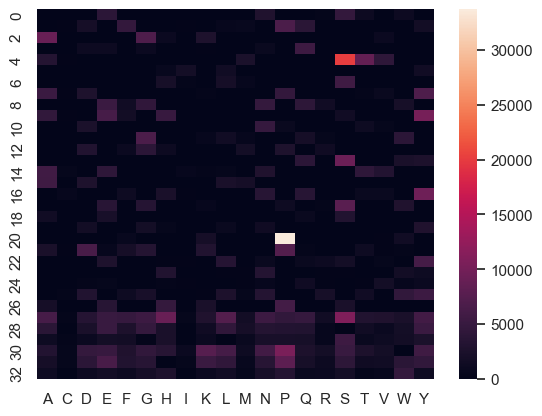

In [37]:
import seaborn as sns
sns.heatmap(df[df.columns[:-1]])

In [38]:
plot_distributions_for_states(model_to_train,f"test{iteration}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
make_pyviz_graph(model_to_train, f"test{iteration}/", precision=3)

with open(f"test{iteration}/model.png", 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)

Converting graph for model (grouped_model) (Delete zero edges)


In [39]:
model_to_train.dense_transition_matrix()[27]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.29725928, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.70274072, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

<AxesSubplot: >

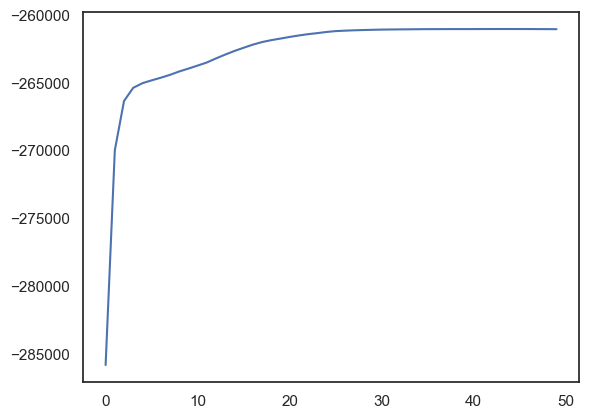

In [40]:
import seaborn as sns

sns.lineplot(probs)

In [41]:
total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]


In [1059]:
f"test{it}/"

'test0/'